# 03 · Feature engineering

**Question:** how do we turn 7 seconds of audio into a fixed list of numbers a classical model can use?

The steps are built one at a time on a single clip, then applied to all 479 clean clips. All the code
lives in `src/features.py` and is tested on synthetic signals in `tests/test_features.py`. Two
rules apply throughout:

- **Cry frames only.** Statistics are taken over the cry bursts found in notebook 02, so a clip
  with long pauses isn't diluted by silence.
- **No absolute loudness.** How loud a clip is depends on the phone and its distance from the baby, so
  every feature is relative. A test checks that scaling a clip by 0.1 leaves every feature unchanged.

The notebook ends with a test of whether the features still carry the recording format
(8 vs 44.1 kHz), which is mixed up with the labels in this dataset (notebook 01).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import dct
from scipy.stats import kruskal
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, SR, load_audio, load_clean_index
from src.descriptors import FRAME, HOP, N_FFT, cry_mask, power_spectrum, rms_db, segments
from src.features import (BAND, GROUPS, N_MELS, N_MFCC, bandlimit, deltas, feature_table,
                          group_of, log_mel, mel_filterbank)

viz.set_style()
pd.set_option("display.width", 140)
idx = load_clean_index()
ex = idx.groupby("label").sample(1, random_state=0).query("label == 'belly_pain'").index[0]
y = load_audio(idx.loc[ex, "path"])
print(f"{len(idx)} clips. Example: a belly_pain clip, {len(y) / SR:.2f} s")

479 clips. Example: a belly_pain clip, 7.00 s


## 1. Frames and the power spectrum

Sound changes from moment to moment, so it is analysed in short **frames**: 25 ms (200 samples)
every 10 ms, the same grid as in notebook 02. Each frame is multiplied by a **Hann window**,
which fades it in and out so the cut edges don't add false high frequencies. The Fourier
transform of the windowed frame (256 points) gives the **power spectrum**: how much energy
there is at each frequency from 0 to 4 kHz, in 31 Hz steps.

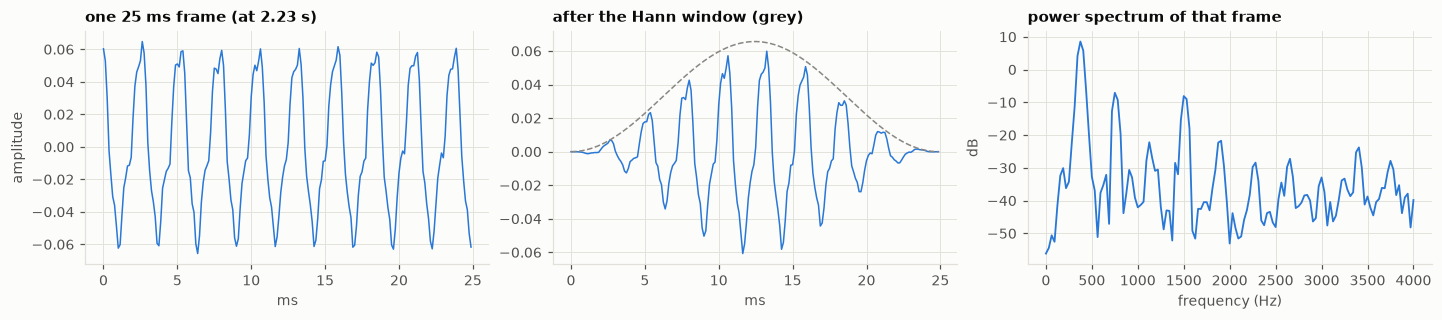

In [2]:
level = rms_db(y)
t = int(np.argmax(level))                     # the loudest frame
frame = y[t * HOP: t * HOP + FRAME]
window = np.hanning(FRAME)
freqs, P = power_spectrum(y)

fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), constrained_layout=True)
ms = np.arange(FRAME) / SR * 1000
axes[0].plot(ms, frame, color=viz.BLUE, lw=1)
axes[0].set(title=f"one 25 ms frame (at {t * HOP / SR:.2f} s)", xlabel="ms", ylabel="amplitude")
axes[1].plot(ms, frame * window, color=viz.BLUE, lw=1)
axes[1].plot(ms, window * np.abs(frame).max(), color=viz.GREY, lw=1, ls="--")
axes[1].set(title="after the Hann window (grey)", xlabel="ms")
axes[2].plot(freqs, 10 * np.log10(P[t] + 1e-12), color=viz.BLUE, lw=1.2)
axes[2].set(title="power spectrum of that frame", xlabel="frequency (Hz)", ylabel="dB")
plt.show()

## 2. Mel filterbank and log-mel spectrogram

Hearing resolves low frequencies finely and high frequencies coarsely. The **mel scale** copies
this. 40 triangular filters, equally spaced in mel, add up the power spectrum into 40 bands:
narrow ones at the bottom, wide ones at the top. Taking the log (in dB) gives the **log-mel
spectrogram**, the standard input for audio models and the basis of feature groups A and B.

The filters cover **150–3800 Hz**, the default band limit (section 7 explains why); everything
outside that band is filtered out of the audio first. The lowest filters are narrower than the
31 Hz spacing of the spectrum and cover only one or two of its bins, which is why their peaks look
uneven.

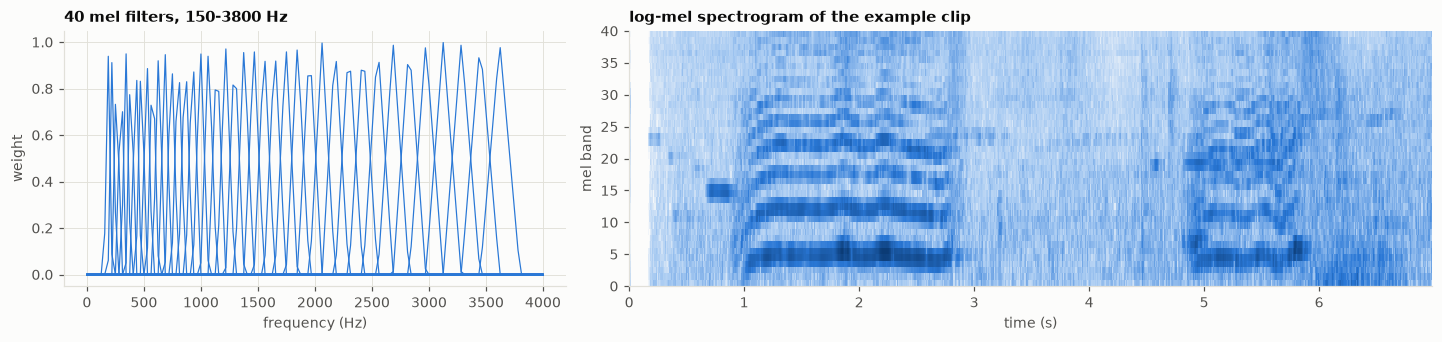

In [3]:
fb = mel_filterbank(fmin=BAND[0], fmax=BAND[1])
yb = bandlimit(y)
_, Pb = power_spectrum(yb)
mel = log_mel(Pb, fb)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.0), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.6]})
for row in fb:
    axes[0].plot(freqs, row, color=viz.BLUE, lw=0.8)
axes[0].set(title=f"{N_MELS} mel filters, {BAND[0]:g}-{BAND[1]:g} Hz", xlabel="frequency (Hz)", ylabel="weight")
axes[1].imshow(mel.T, origin="lower", aspect="auto", cmap=viz.SPEC_CMAP, interpolation="nearest",
               extent=[0, len(mel) * HOP / SR, 0, N_MELS], vmin=mel.max() - 70)
axes[1].grid(False)
axes[1].set(title="log-mel spectrogram of the example clip", xlabel="time (s)", ylabel="mel band")
plt.show()

## 3. MFCC and deltas

Neighbouring mel bands are strongly correlated. A **discrete cosine transform** of each log-mel
frame compresses them into **MFCCs** (mel-frequency cepstral coefficients). Low coefficients
describe the broad shape of the spectrum, higher ones finer ripples such as harmonics. Coefficient
0 is the overall level, i.e. loudness, so it is dropped and coefficients 1–20 are kept.

**Deltas** (Δ) measure how each coefficient changes over time: a regression over ±2 frames.
Delta-deltas (ΔΔ) are the deltas of the deltas, a kind of acceleration. Outside the cry bursts
the deltas are mostly noise, which is another reason statistics use cry frames only.

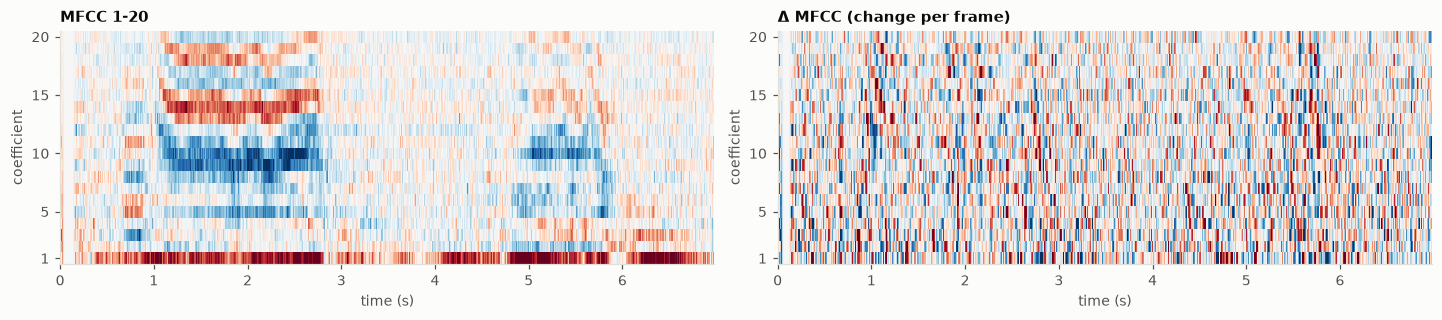

In [4]:
mfcc = dct(mel, type=2, norm="ortho", axis=1)[:, 1:N_MFCC + 1]
d1 = deltas(mfcc)

fig, axes = plt.subplots(1, 2, figsize=(13, 2.8), constrained_layout=True)
for ax, m, title in [(axes[0], mfcc, "MFCC 1-20"), (axes[1], d1, "Δ MFCC (change per frame)")]:
    lim = np.percentile(np.abs(m), 99)
    ax.imshow(m.T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
              extent=[0, len(m) * HOP / SR, 0.5, N_MFCC + 0.5], interpolation="nearest")
    ax.grid(False)
    ax.set_yticks([1, 5, 10, 15, 20])
    ax.set(title=title, xlabel="time (s)", ylabel="coefficient")
plt.show()

## 4. The feature groups

Each clip becomes one row. For frame-level measurements, the row holds the **mean and standard
deviation over cry frames**.

| group | what | features |
|---|---|---|
| **A** log-mel bands | mean (relative to the clip's overall mean, so no loudness) and std of each of the 40 bands | 80 |
| **B** MFCC | mean and std of MFCC 1–20, their Δ and their ΔΔ | 120 |
| **C** spectral shape | mean and std of centroid, bandwidth, 85% roll-off, flatness (noise-like = 1, tonal ≈ 0), flux (frame-to-frame change) | 10 |
| **D** pitch and voicing | median pitch; pitch spread (IQR) and range (5th–95th percentile) in semitones; median frame-to-frame pitch change; voiced share; median aperiodicity | 6 |
| **E** rhythm | share of the clip crying; bursts per second; median and longest burst; median pause | 5 |
| **F** energy dynamics | std, 10th–95th percentile range and median frame-to-frame change of the level in cry frames; cry level minus background level | 4 |

The count below is computed from the actual table.

In [5]:
X = feature_table(BAND)          # computed once (about 20 s) and cached in data/features/, which git ignores
X_full = feature_table(None)     # same features without the band limit, for the leak test and notebook 05

counts = pd.Series([group_of(c) for c in X.columns]).value_counts().sort_index()
print(pd.DataFrame({"group": [GROUPS[g] for g in counts.index], "features": counts.values}, index=counts.index).to_string())
print(f"total: {X.shape[1]} features x {X.shape[0]} clips")
missing = X.isna().sum()
print("\nmissing values (imputed later, inside each training fold):")
print(missing[missing > 0].to_string())

               group  features
A      log-mel bands        80
B               MFCC       120
C     spectral shape        10
D  pitch and voicing         6
E             rhythm         5
F    energy dynamics         4
total: 225 features x 479 clips

missing values (imputed later, inside each training fold):
D_f0_median_hz       3
D_f0_iqr_st          3
D_f0_range_st        3
D_f0_change_st       4
E_pause_median_s    14


In [6]:
# The example clip's row, a few features from each group
X.loc[ex, [c for g in "ABCDEF" for c in [c for c in X.columns if group_of(c) == g][:2]]].round(3).to_frame("example clip")

,example clip
A_mel00_mean,-5.283
A_mel00_std,8.012
B_mfcc01_mean,27.684
B_mfcc01_std,9.519
C_centroid_hz_mean,583.120
C_centroid_hz_std,164.798
D_f0_median_hz,352.467
D_f0_iqr_st,1.105
E_cry_fraction,0.464
E_bursts_per_s,0.429


## 5. Which features differ between classes? (explanation only)

As in notebook 02, values are first reduced to **one per baby per class** (the median), then
compared with a Kruskal–Wallis test. ε² is the effect size, the share of rank variance explained
by the class.

This section is **for understanding only**. Nothing here is used to choose features. Choosing
features using all the data and then cross-validating on the same data would leak test
information into training. Any selection happens later, inside the training folds.

0 of 225 features differ between classes after Holm correction
       count  median eps2  max eps2
group                              
A       80.0       -0.006     0.038
B      120.0       -0.002     0.032
C       10.0       -0.008     0.029
D        6.0       -0.001     0.013
E        5.0        0.006     0.018
F        4.0        0.001     0.007


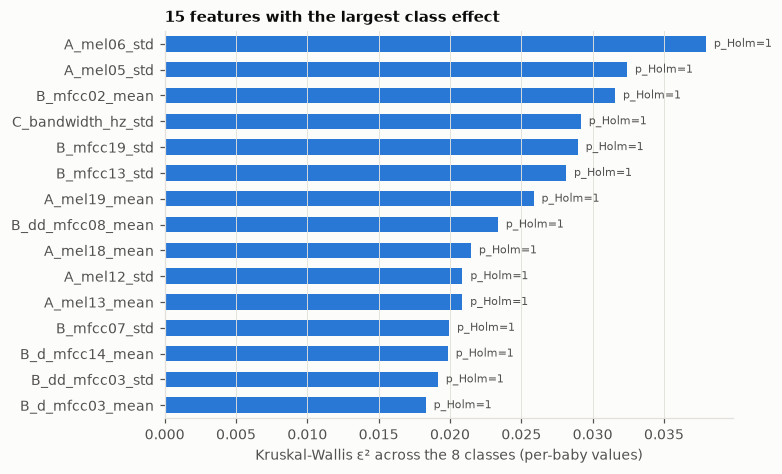

In [7]:
def holm(p):
    p = np.asarray(p, dtype=float)
    adjusted, running = np.empty_like(p), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(running, 1.0)
    return adjusted


baby = X.groupby([idx["label"], idx["source"]]).median()
labels = baby.index.get_level_values("label")
rows = []
for c in X.columns:
    groups = [baby.loc[labels == k, c].dropna() for k in CLASSES]
    H, p = kruskal(*groups)
    n = sum(map(len, groups))
    rows.append({"feature": c, "group": group_of(c), "eps2": (H - len(CLASSES) + 1) / (n - len(CLASSES)), "p": p})
effects = pd.DataFrame(rows).set_index("feature")
m = len(effects)
effects["p (Holm)"] = holm(effects["p"])

print(f"{(effects['p (Holm)'] < 0.05).sum()} of {m} features differ between classes after Holm correction")
print(effects.groupby("group")["eps2"].describe()[["count", "50%", "max"]].round(3).rename(columns={"50%": "median eps2", "max": "max eps2"}).to_string())

top = effects.nlargest(15, "eps2")
fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.barh(range(len(top)), top["eps2"], color=viz.BLUE, height=0.6)
ax.set_yticks(range(len(top)), top.index)
ax.set_ylim(len(top) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Kruskal-Wallis ε² across the 8 classes (per-baby values)", title="15 features with the largest class effect")
for i, (e, p) in enumerate(zip(top["eps2"], top["p (Holm)"])):
    ax.text(e, i, f"  p_Holm={p:.2g}", va="center", fontsize=7, color=viz.INK_2)
plt.show()

feature pairs: 25200; with |Spearman r| > 0.9: 42; > 0.7: 454


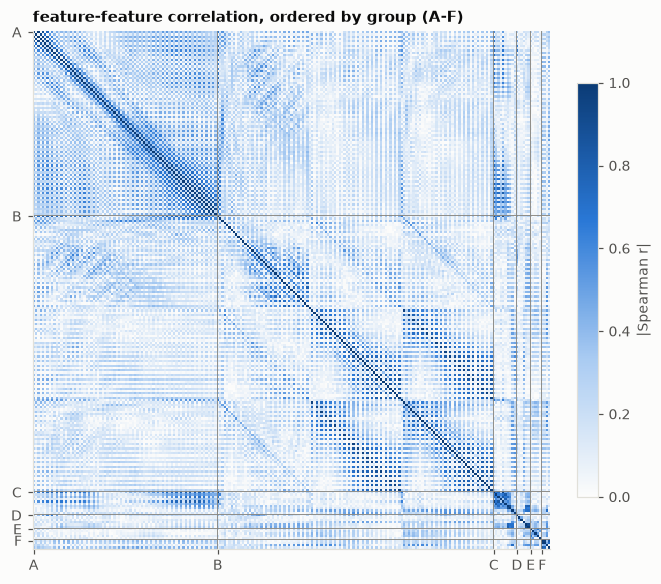

In [8]:
# Redundancy: how strongly do features overlap?
corr = X.corr(method="spearman").abs()
upper = corr.to_numpy()[np.triu_indices(len(corr), k=1)]
print(f"feature pairs: {len(upper)}; with |Spearman r| > 0.9: {(upper > 0.9).sum()}; > 0.7: {(upper > 0.7).sum()}")

fig, ax = plt.subplots(figsize=(6, 5.2), constrained_layout=True)
im = ax.imshow(corr.to_numpy(), cmap=viz.SPEC_CMAP, vmin=0, vmax=1, interpolation="nearest")
ax.grid(False)
starts = pd.Series([group_of(c) for c in X.columns]).drop_duplicates()
ax.set_xticks(starts.index, starts.values)
ax.set_yticks(starts.index, starts.values)
for s in starts.index[1:]:
    ax.axhline(s - 0.5, color=viz.GREY, lw=0.6)
    ax.axvline(s - 0.5, color=viz.GREY, lw=0.6)
fig.colorbar(im, ax=ax, label="|Spearman r|", shrink=0.8)
ax.set_title("feature-feature correlation, ordered by group (A-F)")
plt.show()

## 6. Do the features still carry the recording format?

Notebook 01 found two formats: 8 kHz mono and 44.1 kHz stereo. They line up with the labels:
*hungry* and *belly_pain* are all 8 kHz, while *cold_hot*, *lonely* and *scared* are all 44.1 kHz.
All audio is converted to 8 kHz, but the recording chain (codec, filters) may still leave a trace. If
it does, a model could "recognise" *lonely* by its format instead of by the cry.

Testing format directly on all clips can't tell format from class, since the two move together. So the test
holds the class fixed:

- **Train** a format detector (standardise → logistic regression, fixed settings, nothing tuned)
  only on the five single-format classes. Babies that also appear in the test set are left out.
- **Test** it on the three classes that contain **both** formats: *tired*, *discomfort*, *burping*.
  The detector has never seen these classes, so it can only rank their 44.1 kHz clips above their 8 kHz
  clips by picking up the format itself.
- **AUROC** is the chance that a random 44.1 kHz test clip scores higher than a random 8 kHz one:
  0.5 means no trace of the format, 1 means perfect detection.

**Decided before running:** band-limiting to 150–3800 Hz (dropping the edges where notebook 01
saw the formats differ) is the default whatever this shows. The full-band features are kept as a
sensitivity check for notebook 05.

**Limitation:** the test set holds only 6 clips at 44.1 kHz, from 4 babies, so the AUROC is
imprecise. Below, it is also recomputed with each of those babies left out.

In [9]:
fmt = (idx["sample_rate"] == 44100).astype(int).to_numpy()
mixed = idx["label"].isin(["tired", "discomfort", "burping"]).to_numpy()
train = ~mixed & ~idx["source"].isin(set(idx.loc[mixed, "source"])).to_numpy()
print(f"train: {train.sum()} clips ({fmt[train].sum()} at 44.1 kHz) from {idx.loc[train, 'source'].nunique()} babies")
print(f"test:  {mixed.sum()} clips ({fmt[mixed].sum()} at 44.1 kHz, from "
      f"{idx.loc[mixed & (fmt == 1), 'source'].nunique()} babies) in tired, discomfort, burping")


def format_detector():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))


def leak_auc(table, columns):
    model = format_detector().fit(table.loc[train, columns], fmt[train])
    scores = model.predict_proba(table.loc[mixed, columns])[:, 1]
    return roc_auc_score(fmt[mixed], scores), scores


test_src = idx.loc[mixed, "source"].to_numpy()
rows, scores = [], {}
for name, table in [("full band 0-4 kHz", X_full), ("band-limited 150-3800 Hz", X)]:
    auc, s = leak_auc(table, list(table.columns))
    scores[name] = s
    without = [roc_auc_score(fmt[mixed][test_src != b], s[test_src != b])
               for b in np.unique(test_src[fmt[mixed] == 1])]
    row = {"features": name, "AUROC all groups": auc,
           "AUROC leaving out one 44.1 kHz baby (min-max)": f"{min(without):.2f}-{max(without):.2f}"}
    for g in GROUPS:
        row[f"AUROC {g} only"] = leak_auc(table, [c for c in table.columns if group_of(c) == g])[0]
    rows.append(row)
leak = pd.DataFrame(rows).set_index("features")
leak.round(2).T

train: 374 clips (20 at 44.1 kHz) from 191 babies
test:  58 clips (6 at 44.1 kHz, from 4 babies) in tired, discomfort, burping


features,full band 0-4 kHz,band-limited 150-3800 Hz
AUROC all groups,0.86,0.82
AUROC leaving out one 44.1 kHz baby (min-max),0.85-0.86,0.80-0.85
AUROC A only,0.88,0.73
AUROC B only,0.75,0.83
AUROC C only,0.74,0.67
AUROC D only,0.54,0.54
AUROC E only,0.27,0.26
AUROC F only,0.62,0.6


ranks of the 44.1 kHz clips among the 58 (1 = most 44.1-like): [5, 9, 11, 13, 15, 24]


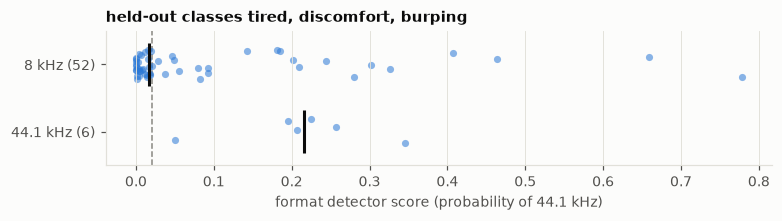

In [10]:
# The detector's scores on the 58 held-out clips (band-limited features)
s = scores["band-limited 150-3800 Hz"]
test = idx.loc[mixed, ["label", "sample_rate"]].assign(score=s)
test["format"] = np.where(test["sample_rate"] == 44100, "44.1 kHz", "8 kHz")
rank = test["score"].rank(ascending=False).astype(int)
print("ranks of the 44.1 kHz clips among the 58 (1 = most 44.1-like):", sorted(rank[test["format"] == "44.1 kHz"]))

fig, ax = plt.subplots(figsize=(7, 1.9), constrained_layout=True)
viz.strip_by_class(ax, test, "score", by="format", order=["8 kHz", "44.1 kHz"], size=22)
ax.set_xlabel("format detector score (probability of 44.1 kHz)")
ax.set_title("held-out classes tired, discomfort, burping")
plt.show()

In [11]:
# A second remedy: drop the per-band means of groups A and B (they mostly encode the channel's
# frequency response) and keep variability, deltas and the other groups
no_means = [c for c in X.columns if not (c.startswith(("A_", "B_mfcc")) and c.endswith("_mean"))]
print(f"band-limited, without A/B means ({len(no_means)} features): AUROC {leak_auc(X, no_means)[0]:.2f}")

band-limited, without A/B means (165 features): AUROC 0.76


## 7. Findings

All numbers below are printed by the cells above.

1. **225 features per clip**: 80 log-mel band statistics (A), 120 MFCC statistics (B), 10 spectral
   shape (C), 6 pitch and voicing (D), 5 rhythm (E), 4 energy dynamics (F). Values are missing only
   where they are undefined: pitch features for 3–4 clips with too little voicing, and the median
   pause for 14 clips that contain a single burst. Notebook 05 fills them in inside each training
   fold, using that fold's medians only.
2. **Every feature is weak on its own.** None of the 225 differs between the classes after Holm
   correction, and the largest effect is ε² = 0.038. This matches notebook 02. Any usable signal has
   to come from combinations of features, which is what the models in notebook 05 try.
3. **There is redundancy, but it is limited.** 42 of 25,200 feature pairs have |Spearman r| > 0.9,
   and 454 have > 0.7. Most of it lies between neighbouring mel bands (A) and among the
   spectral-shape features (C). Nothing is pruned here, because doing so on all clips would be
   selection outside the cross-validation. Regularised and tree models handle correlated inputs.
4. **The recording format still shows through.** A format detector trained only on other classes ranks the
   six 44.1 kHz clips of *tired*, *discomfort* and *burping* above most of the 52 8 kHz clips of the
   same classes (ranks 5–24 of 58). The AUROC is 0.86 with full-band features and 0.82
   band-limited (0.80–0.85 when any one of the 4 babies is left out). Dropping the per-band means
   as well gives 0.76. Band-limiting mainly weakens the log-mel band means (group A: 0.88 → 0.73),
   while the MFCC group gets slightly *stronger* (0.75 → 0.83). Neither remedy removes the trace.
   With 6 clips from 4 babies the exact values are imprecise, but every version is well above 0.5.
   The rhythm group scores 0.26, i.e. *below* 0.5. That part of the detector learned class
   differences (*cold_hot*/*lonely*/*scared* vs *hungry*/*belly_pain*) that reverse in the held-out
   classes. So the test cannot fully separate "format" from "sounds like the 44.1 kHz classes".
5. **What happens next.** As decided before running, the **band-limited 225 features are the
   default**, and notebook 05 also reports the full-band set. Results for *cold_hot*, *lonely* and
   *scared* must be read knowing that a model may partly recognise the recording chain. Notebook 06
   tests this on the class model itself: are the six 44.1 kHz clips of *tired*, *discomfort* and *burping*
   predicted as *cold_hot*, *lonely* or *scared* more often than the 8 kHz clips of those classes?